# ANOVA, Chi-Square, and Complexity

Permutation ANOVA, chi-square association testing, and written complexity analysis of distributed Bloom filters.

Originally developed for CSCI 443 at the University of Mississippi. Assignment prompts and provided teaching examples are course material; this notebook contains my submitted responses and code.

Saved outputs are retained from the uploaded coursework. This packaged copy has not been rerun end to end. See the repository README for required data and review notes.


## Part 1: Permutation ANOVA: Does Debugging Snack Affect Completion Time?

A professor wants to know whether the snack given during lab affects how long students take to fix a buggy program.

The file `debugging_snacks.csv` contains simulated completion times for four snack groups:

- No snack
- Trail mix
- Energy bar
- Gummy worms

**1.1.** Load the CSV file and compute the mean, median, and standard deviation of completion time for each snack group.

**1.2.** Create a boxplot for each group.  Do any of the groups look skewed?  Why?  Do these look Gaussian?

**1.3.** State the null and alternative hypotheses for a one-way ANOVA.

**1.4.** Explain why a permutation ANOVA is more appropriate than relying only on classical ANOVA assumptions.

**1.5.** Compute the observed ANOVA F-statistic.

**1.6.** Perform a permutation ANOVA by repeatedly shuffling the snack labels while keeping the completion times fixed.

**1.7.** Estimate the p-value:

   \[
   p = \frac{\text{number of permuted F-statistics at least as large as observed F}}{\text{number of permutations}}
   \]

**1.8.** At α = 0.05, determine whether to reject the null hypothesis.

**1.9.** Briefly interpret the result.

In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f_oneway

df = pd.read_csv("/Volumes/workspace/default/files/debugging_snacks.csv")

df.head()

,snack,completion_time_minutes
0,No snack,55.06
1,No snack,53.44
2,No snack,52.78
3,No snack,47.18
4,No snack,41.52


In [0]:
#1.1
summary = df.groupby("snack")["completion_time_minutes"].agg(["mean", "median", "std"])
summary

,mean,median,std
snack,,,
Energy bar,51.995867,46.28,19.755798
Gummy worms,50.237600,45.94,26.233364
No snack,51.941733,52.26,6.679851
Trail mix,48.422667,47.75,9.673531


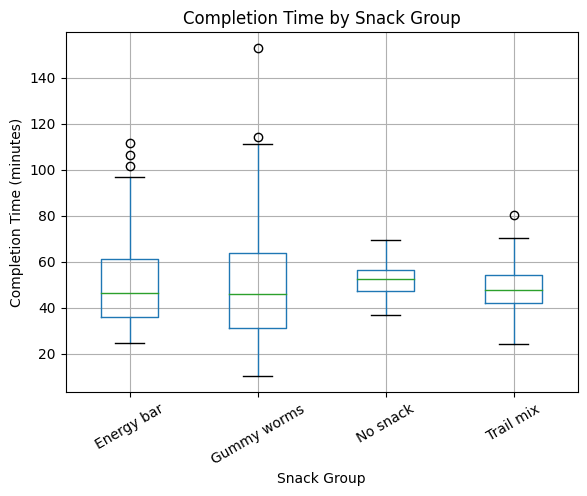

In [0]:
#1.2
df.boxplot(column="completion_time_minutes", by="snack")
plt.title("Completion Time by Snack Group")
plt.suptitle("")
plt.xlabel("Snack Group")
plt.ylabel("Completion Time (minutes)")
plt.xticks(rotation=30)
plt.show()

1.3 Hypotheses

H0: All snack groups have the same mean completion time

H1: At least one group has a different mean completion time

### Why use a permutation comparison?

A permutation test constructs a null distribution by shuffling group labels. It avoids a parametric normality model but still requires exchangeability under the null. It is not automatically robust to unequal variances. Classical one-way ANOVA also relies on independent observations and equal group variances, with normality supporting its exact small-sample inference.


In [0]:
#1.5
groups = [group["completion_time_minutes"].values for name, group in df.groupby("snack")]

observed_F, classical_p = f_oneway(*groups)

print("Observed F-statistic:", observed_F)
print("Classical ANOVA p-value:", classical_p)

Observed F-statistic: 0.7077480361263785
Classical ANOVA p-value: 0.5480318496579009


**Monte Carlo note:** The preserved code estimates the permutation p-value as `extreme / B`. For a randomized test, `(extreme + 1) / (B + 1)` avoids zero estimates. Here the stored result is about 0.55, so that adjustment does not alter the decision at 0.05.

In [0]:
#1.6 - 1.7
np.random.seed(42)

num_permutations = 10000
observed_F = f_oneway(*groups).statistic

permuted_F_stats = []

for i in range(num_permutations):
    shuffled_labels = np.random.permutation(df["snack"].values)
    
    temp_df = df.copy()
    temp_df["shuffled_snack"] = shuffled_labels
    
    shuffled_groups = [
        group["completion_time_minutes"].values
        for name, group in temp_df.groupby("shuffled_snack")
    ]
    
    permuted_F = f_oneway(*shuffled_groups).statistic
    permuted_F_stats.append(permuted_F)

permuted_F_stats = np.array(permuted_F_stats)

p_value = np.mean(permuted_F_stats >= observed_F)

print("Observed F-statistic:", observed_F)
print("Permutation p-value:", p_value)

Observed F-statistic: 0.7077480361263785
Permutation p-value: 0.5503


1.8 Decision at α = 0.05

Since the permutation p-value is about 0.55, which is greater than 0.05, we fail to reject the null hypothesis.

1.9 Interpretation

There is not enough evidence to conclude that the type of snack affects the average completion time. Although the groups have slightly different means, those differences are small compared to the variation within the groups, especially for Energy bar and Gummy worms. Therefore, based on this permutation ANOVA, snack type does not appear to have a statistically significant effect on debugging completion time.

## Part 2: Chi-Square - Caffeine and Coding Style

A professor suspects that preferred caffeinated beverage and preferred programming style are independent. A survey of students asked which drink they prefer among those listed and their preferred coding style produced the following observed counts:

| Beverage                     | Functional | Object-Oriented | Just Make It Work | Total |
|-----------------------------|-----------:|----------------:|------------------:|------:|
| Black coffee / espresso     | 24         | 10              | 6                 | 40    |
| Latte                       | 8          | 28              | 14                | 50    |
| Foo Bar Energy drink        | 8          | 7               | 25                | 40    |
| **Total**                   | **40**     | **45**          | **45**            | **130** |

**2.1.** State the null and alternative hypotheses.

**2.2.** Compute the expected count for each cell:

   \[
   E_{ij} = \frac{(\text{row total})(\text{column total})}{\text{grand total}}
   \]

Create a new cell by copying and pasting from the one above and adding the expected values
in parenthesis to each cell.

**2.3.** Compute the chi-squared statistic:

   \[
   \chi^2 = \sum \frac{(O - E)^2}{E}
   \]

**2.4.** Compute the degrees of freedom.

**2.5.** At α = 0.05, determine whether to reject the null hypothesis.

**2.6.** Briefly interpret the result. Which beverage/coding-style pair contributes most strongly to the result?

2.1 Hypotheses

H0: Preferred beverage and preferred coding style are independent

H1: Preferred beverage and preferred coding style are not independent

In [0]:
#2.2
import numpy as np
import pandas as pd

# Observed counts
observed = pd.DataFrame({
    "Functional": [24, 8, 8],
    "Object-Oriented": [10, 28, 7],
    "Just Make It Work": [6, 14, 25]
}, index=["Black coffee / espresso", "Latte", "Energy drink"])

# Totals
row_totals = observed.sum(axis=1)
col_totals = observed.sum(axis=0)
grand_total = observed.values.sum()

# Expected counts
expected = pd.DataFrame(index=observed.index, columns=observed.columns)

for i in observed.index:
    for j in observed.columns:
        expected.loc[i, j] = (row_totals[i] * col_totals[j]) / grand_total

expected = expected.astype(float)

display(observed)
display(expected)

Functional,Object-Oriented,Just Make It Work
24,10,6
8,28,14
8,7,25


Functional,Object-Oriented,Just Make It Work
12.307692307692308,13.846153846153847,13.846153846153847
15.384615384615385,17.307692307692307,17.307692307692307
12.307692307692308,13.846153846153847,13.846153846153847


Black coffee / espresso:
24 (12.31), 10 (13.85), 6 (13.85)

Latte:
8 (15.38), 28 (17.31), 14 (17.31)

Energy drink:
8 (12.31), 7 (13.85), 25 (13.85)

In [0]:
#2.3
chi_square = ((observed - expected) ** 2 / expected).values.sum()
print("Chi-square statistic:", chi_square)

Chi-square statistic: 41.282222222222224


In [0]:
#2.4
df = (3 - 1) * (3 - 1)
print(df)

4


In [0]:
#2.5
from scipy.stats import chi2

p_value = 1 - chi2.cdf(chi_square, df)
print("p-value:", p_value)

p-value: 2.3494104661736515e-08


Since the p-value is 2.35 × 10⁻⁸, which is much smaller than 0.05, we reject the null hypothesis.


There is evidence of an association between preferred beverage and coding style in this exercise (chi-square ≈ 41.28, p ≈ 2.35 × 10⁻⁸). The largest individual contribution is the Black coffee / espresso–Functional cell (about 11.11), followed by the Energy drink–Just Make It Work cell (about 8.98). This association does not establish causation.


## Part 3: Spark Performance Analysis: Distributed Bloom Filter

We have recently hired a physics professor who studied under Stephen Hawking. 
He suspects that a few students in the class are actually time travelers 
who have enrolled multiple times across different centuries at different
universities around the world.

He has compiled a large database of prior students from the United States,
the United Kingdom, and many other European countries.

The dataset contains `n` records of prior students distributed across 
`p` Spark partitions. We want to build a Bloom filter so that later queries can test whether newly enrolled students were probably present in the original dataset. If a student is reported as probably present, we will investigate further.

We use a Bloom filter because it supports cheap approximate membership 
queries. It may produce false positives, but it should not produce false
negatives under the standard insert-only model.  If we find a 
possible positive, we will investigate further to determine the veracity
of the match.

The Bloom filter has:

- `m` bits

- `k` hash functions

Each partition builds a local Bloom filter. The local Bloom filters are then combined using bitwise OR through a tree-reduction.

**3.1.** Read about Bloom filters and explain what a Bloom filter guarantees:

- What kind of error is possible?

- What kind of error is not possible?

**3.2.** Analyze executor time complexity.

**3.3.** Analyze executor memory complexity.

**3.4.** Analyze driver time complexity.

**3.5.** Analyze driver memory complexity.

**3.6.** Analyze total work.

**3.7.** Analyze network volume.

**3.8.** How many full-data shuffles are required?

**3.9.** How many actions are required?

**3.10.** Could you perform exact membership queries by first sorting the entire dataset? Compare using a Bloom filter with sorting the full dataset. How do the time and space costs compare for the executor and driver? What is gained, and what is lost?


3.1 

A Bloom filter is an approximate membership data structure. It can produce false positives, meaning it may say a student was probably in the original dataset even if they were not. However, under the standard insert-only model, it should not produce false negatives, meaning if a student really was inserted into the Bloom filter, the Bloom filter should report them as probably present.

3.2 

Each record is processed once by an executor. For each record, the executor applies k hash functions and sets k bits in the local Bloom filter. If there are n total records across p partitions, each partition handles about n/p records.

Executor time per partition: O((n/p) * k)

3.3

Each executor partition builds a local Bloom filter with m bits. Therefore, the memory needed per partition is:

O(m)

This does not depend directly on the number of records in the partition, because the Bloom filter size is fixed.

3.4 

The driver receives the final combined Bloom filter after the tree-reduction. Since the filters are combined using bitwise OR, combining two filters takes O(m) time. With p local filters, the total combine work is approximately:

O(pm)

However, because Spark uses tree-reduction, this work is distributed rather than all being done sequentially on the driver.

3.5 

The driver only needs to store the final Bloom filter of size m bits. Therefore, driver memory is:

O(m)

The driver does not need to store all n student records.

3.6 

The total work includes inserting all n records into local Bloom filters and combining the p local filters.

Insertion work:

O(nk)

Reduction work:

O(pm)

Total work:

O(nk+pm)

3.7

Each partition sends a Bloom filter of size m bits during the tree-reduction. Since there are p partitions, the network volume is approximately:

O(pm)

This is much smaller than sending all n records if m is small compared to the dataset size.

3.8 

No full-data shuffle is required. The records do not need to be grouped, sorted, or redistributed by key. Each partition builds a local Bloom filter independently, and only the compact Bloom filters are combined.

Answer: 0 full-data shuffles.

3.9 

Building the Bloom filter requires one Spark action, such as a treeReduce or collect-style reduction of the local Bloom filters.

Answer: 1 action.

3.10 

Sorting the full dataset requires O(n log n) time and a full shuffle of all data. It also uses much more memory because the entire dataset must be stored and moved.

The Bloom filter approach uses O(n * k + p * m) time, much less network traffic, and only O(m) memory per executor and driver.

Bloom filter advantage: faster, less memory, less network cost
Bloom filter disadvantage: may produce false positives

Sorting advantage: exact results (no false positives)
Sorting disadvantage: slower, expensive, requires full shuffle